# Miniproyecto — Diseño de un pipeline ETL con fuentes heterogéneas

**Módulo:** Extracción, Transformación y Carga de Datos desde Fuentes Múltiples (5104)  
**Alumno/a:**  
**Fecha de entrega:**  

---

## ¿En qué consiste este miniproyecto?

El objetivo es que diseñes —sin implementarlo— un pipeline ETL completo que combine **al menos dos fuentes de datos heterogéneas** para producir un único dataset limpio y listo para ser analizado.

Una de las fuentes debe proporcionar datos **en tiempo real o con actualización frecuente** (cada pocos minutos u horas), y otra debe ser un **formulario** cuyos datos se acumulan a medida que los usuarios lo van rellenando. Cada fila del dataset final corresponde a una respuesta del formulario, enriquecida con los datos de la fuente en tiempo real recogidos en el momento en que se rellenó.

No vas a escribir código: vas a pensar, describir y diseñar. Eso es exactamente lo que hace un ingeniero/a de datos antes de ponerse a programar.


---
## Proyectos propuestos

Puedes elegir uno de los dos proyectos siguientes, o proponer el tuyo propio (consulta los requisitos al final de este apartado).

---

### Proyecto A — Polen y síntomas de alergia en Granada

Granada tiene una de las concentraciones de Polen de olivo más altas de Europa, especialmente entre abril y junio. Muchas personas no saben si sus síntomas (picor de ojos, estornudos, fatiga) están relacionados con el Polen o con otros factores.

La idea es recoger síntomas diarios de un grupo de personas mediante un formulario, y combinarlos automáticamente con los datos de calidad del aire y concentración de Polen del momento en que rellenaron el formulario. El dataset resultante permitiría estudiar si hay correlación entre el índice de Polen y la intensidad de los síntomas.

**Fuentes de datos disponibles:**

- **Formulario de síntomas** (Google Forms): el usuario indica cada día sus síntomas,   su medicación y cómo se encuentra en general.
- **API Open-Meteo Air Quality** (`https://air-quality-api.open-meteo.com/v1/air-quality`):   devuelve concentración de Polen de gramíneas, olivo y arizónica, además de PM2.5 y ozono,   actualizada cada hora, sin necesidad de clave API.

---

### Proyecto B — Rendimiento deportivo y condiciones ambientales

¿Entrenas peor cuando hace mucho calor? ¿La humedad afecta a tu resistencia? Este proyecto busca recoger registros de entrenamientos de un grupo de deportistas y cruzarlos con las condiciones meteorológicas del momento en que entrenaron.

El dataset final permitiría analizar si la temperatura, la humedad o el viento tienen impacto en el rendimiento percibido o en las métricas objetivas del entrenamiento.

**Fuentes de datos disponibles:**

- **Formulario de entrenamiento** (Google Forms): el deportista registra al terminar   el entrenamiento el tipo de deporte, duración, distancia, esfuerzo percibido (1-10)   y sensación general.
- **API Open-Meteo** (`https://api.open-meteo.com/v1/forecast`): temperatura, humedad   relativa, velocidad del viento, índice UV y precipitación, actualizada cada 15 minutos,   sin clave API.

---

### Proyecto C — Propuesta propia

Si tienes otra idea, puedes desarrollarla siempre que cumpla estos requisitos:

- Al menos **dos fuentes** de datos heterogéneas.
- Una fuente debe ser un **formulario** (Google Forms u otro).
- Otra fuente debe ser una **API pública** con datos que se actualicen al menos cada hora.
- El dataset final debe tener sentido: cada fila representa una observación real   enriquecida con datos externos del mismo instante.

Antes de desarrollarla, descríbela brevemente aquí para asegurarte de que cumple los requisitos:

*Si vas a proponer tu propio proyecto, descríbelo aquí en 5-6 líneas:*



---
## Mi elección

Indica qué proyecto has elegido y por qué (2-3 frases):

*Escribe aquí:*

He decidido elegir el proyecto de Rendimiento deportivo y condiciones ambientales.
Me parece el más interesante ya que es el que más se asemeja a mi vida cotidiana.


---
## 1. Descripción de las fuentes de datos

Para cada fuente de datos de tu proyecto, rellena una ficha como la siguiente. Si tu proyecto tiene más de dos fuentes, añade las fichas que necesites.


### Fuente 1 — Formulario

| Campo | Descripción |
|-------|-------------|
| **Nombre** | Formulario informativo sobre entrenamiento |
| **Tipo de fuente** | Formulario web (Google Forms) |
| **URL o acceso** | Se crea un formulario en Google Forms y se comparte el enlace.|
| **Formato de los datos** | Las respuestas se descargan como CSV|
| **Frecuencia de actualización** | Cada vez que el usuario lo rellena |
| **Quién lo rellena** | Participantes del estudio, una vez al día |

**Campos del formulario** (lista todas las preguntas que incluirías):

| Campo | Tipo de dato | Ejemplo de valor |
|-------|-------------|------------------|
| Nombre_usuario| Texto | Josito |
| Edad | Número | 19 |
| Deporte | Texto | Correr al aire libre |
| Duración del ejercicio (min) | Número | 45 min |
| Distancia recorrida | Número | 9km |
| Esfuerzo percibido (1-10) | Número | 4 |

*Edita las tablas con tus datos reales:*



### Fuente 2 — API en tiempo real

| Campo | Descripción |
|-------|-------------|
| **Nombre** | Open-Meteo Climate API |
| **Tipo de fuente** | API REST pública |
| **URL base** | URL del endpoint que usaría |
| **Formato de respuesta** | NdJSON |
| **Frecuencia de actualización** | Streaming (Al instante) |
| **Autenticación necesaria** | Sí |

**Parámetros de la petición** (qué le envías a la API para obtener los datos que necesitas):

| Parámetro | Valor | Para qué sirve |
|-----------------|------|----------------|
| Temperatura | Número | La temperatura en grados del ambiente |
| Humedad relativa | Número | Porcentaje de la humedad en el ambiente |
| Velocidad del viento  | Número | Velocidad del viento (km/h) |
| Índice UV | Número | Índice ultravioleta (1-11+) |
| Precipitación | Número | Cantidad de precipitación (mm) |

**Campos de la respuesta que usarías** (no hace falta listarlos todos, solo los relevantes):

| Campo de la API | Tipo | Qué representa |
|-----------|-------|----------------|
| time | string (datetime ISO) | Marca de tiempo de cada lectura; es el campo que se usa para asociarla al timestamp del formulario |
| temperature_2m | float | Temperatura del aire a 2m de altura, en °C |
| relative_humidity_2m | int | Humedad relativa a 2m de altura, en % |
| wind_speed_10m | float | Velocidad del viento a 10m de altura, en km/h |
| uv_index | float | Índice ultravioleta (1-11+) |
| precipitation | float | Precipitación acumulada en esa hora, en mm |

*Edita las tablas con tus datos reales:*

---
## 2. Diseño del dataset final

Describe el esquema del dataset que producirá tu pipeline. Cada fila representa una respuesta del formulario enriquecida con los datos de la API recogidos en el mismo instante.

### 2.1 Esquema de columnas

| Columna | Tipo | Origen | Descripción |
|---------|------|--------|-------------|
| `timestamp` | datetime | Formulario | Fecha y hora en que se rellenó el formulario |
| Nombre_usuario | str | Formulario | Nombre del usuario que realiza el formulario |
| Edad | int | Formulario | Edad del usuario |
| Deporte | str | Formulario | Deporte que realiza el usuario |
| Duracion_ejercicio | int | Formulario | Duración del ejercicio |
| Distancia_recorrida | int | Formulario | Distancia que recorre el usuario en km |
| Esfuerzo_percibido | int | Formulario | Valoración del esfuerzo del usuario |
| Temperatura | int | API | Temperatura del ambiente en grados |
| Humedad_relativa | int | API | % Humedad del ambiente |
| Velocidad del viento | int | API | Velocidad viento en km/h |
| Índice UV | int | API | Índice ultravioleta(1-11+) |
| Precipitación | int | API | Precipitación acumulada en mm |

*Edita la tabla con las columnas reales de tu dataset:*



### 2.2 Ejemplo de fila

Escribe cómo se vería una fila real (inventada) del dataset final, con valores concretos en cada columna:

```
timestamp          | col_form_1 | col_form_2 | ... | col_api_1 | col_api_2 | ...
2025-05-15 08:32   |    ...     |    ...     | ... |    ...    |    ...    | ...
```

*Escribe aquí tu ejemplo de fila con valores reales:*

```
 Nombre_usuario | Edad | Deporte              | Duracion_ejercicio | Distancia_recorrida | Esfuerzo_percibido |
 Josito         | 19   | Correr al aire libre | 45                  | 9                    | 4 |
```


### 2.3 Formatos de exportación

El dataset final se exportará en los siguientes formatos (indica al menos dos y justifica para qué serviría cada uno):

| Formato | Justificación |
|---------|---------------|
| CSV | Para compartir con investigadores que usan Excel o R, y para que los propios deportistas puedan revisar sus registros fácilmente |
| Parquet | Para análisis y procesamiento posterior con pandas o herramientas de Big Data: ocupa menos espacio, conserva los tipos de dato (int, datetime...) y se lee más rápido que el CSV en datasets grandes |

*Edita la tabla:*



---
## 3. Diseño del pipeline

Describe y dibuja el pipeline completo: cómo fluyen los datos desde las fuentes hasta el dataset final, pasando por la extracción, el almacenamiento intermedio, la limpieza y la combinación.

### 3.1 Descripción por etapas

Explica qué ocurre en cada etapa del pipeline. Sé concreto: no digas solo 'se limpian los datos', sino qué problema concreto se limpia y cómo.


**Etapa 1 — Extracción del formulario**

*Describe aquí cómo se obtienen los datos del formulario: con qué frecuencia se recogen, en qué formato llegan, cómo se accede a ellos programáticamente (ej: Google Sheets API, descarga CSV periódica, webhook...). ¿Qué ocurre si el usuario deja campos en blanco?*



*Escribe aquí:*

Al enviar el formulario, la respuesta se guarda en el Google Sheet vinculado al Form. De ahí se descarga el CSV automáticamente en el momento del envío, así que los datos llegan al instante en que el usuario rellena el formulario. El Form está configurado para que todos los campos sean obligatorios, así que no pueden llegar respuestas con campos en blanco o inválidos.



**Etapa 2 — Extracción de la API en tiempo real**

*Describe cómo se consulta la API: ¿cada cuánto tiempo? ¿Para cada nueva respuesta del formulario o de forma periódica e independiente? ¿Cómo se asocia cada lectura de la API al timestamp exacto de la respuesta del formulario? ¿Qué pasa si la API no responde o devuelve un error?*



*Escribe aquí:*

La API se consulta justo cuando llega una nueva respuesta del formulario, no de forma periódica aparte, porque así se obtiene el dato más fresco posible sin hacer peticiones de más (la API meteorológica solo actualiza cada 15 minutos, consultarla cada pocos segundos no aportaría nada nuevo). El timestamp de la lectura de la API se asocia por cercanía al timestamp de la respuesta del formulario.
Si la llamada a la API falla o no devuelve datos, se usa la última lectura disponible y se marca esa fila para revisarla más tarde, en vez de inventar un valor.



**Etapa 3 — Almacenamiento intermedio**

*¿Dónde y cómo se guardan los datos de cada fuente antes de combinarlos? Por ejemplo: ¿los datos del formulario se guardan en un CSV local, en una BD SQLite, en un Google Sheet? ¿Y los de la API? ¿Con qué nombre de fichero o tabla? ¿Se sobreescriben o se van acumulando?*



*Escribe aquí:*

Los datos se guardan en ficheros locales, no en la nube, para no depender de que haya conexión en el momento de leerlos. Las respuestas del formulario se guardan en DB_Form y las lecturas de la API en DB_API, estos dos ficheros solo contienen la última tanda de datos sin procesar, así que se sobrescriben en cada ciclo.
El resultado de cruzar formulario y API se guarda en result_DB, que sí va acumulando una fila por cada entrenamiento (no se sobrescribe), porque es el dataset que se usa para el análisis final y necesita conservar el histórico completo.


**Etapa 4 — Limpieza y validación**

*Lista al menos 4 problemas de calidad concretos que podrían aparecer en tus datos y cómo los resolverías. Por ejemplo: timestamps en formato incorrecto, valores fuera de rango, respuestas duplicadas del formulario, campos de la API ausentes para ciertos horarios...*

| Problema | Fuente afectada | Cómo se resuelve |
|----------|----------------|------------------|
| Datos exagerados| Formulario | Al poder generar un sesgo en la predicción, se transformarían a un valor mas cercano a la mediana. |
| Problemas en la conexión | API | Al no recibir ningún dato, se podría intentar tomar como referencia el anterior dato que se consultó hace 5seg |
| Valores ausentes | API | Se tendrían que imputar los datos |
| Respuestas duplicadas | Formulario | Si hay respuestas duplicadas con un timestamp también duplicado, solo se tendría en cuenta uno ya que es redundante hacer el calculo dos veces. |

*Edita la tabla:*



**Etapa 5 — Combinación (join) y producción del dataset final**

*Explica cómo se combinan los datos del formulario con los de la API: ¿qué campo se usa para hacer el join (timestamp, coordenadas geográficas...)? ¿Qué pasa si no hay dato de la API exactamente en ese instante: se usa el más cercano en el tiempo, se interpola, se descarta la fila? ¿En qué formato se guarda el dataset final y dónde?*



*Escribe aquí:*

El cruce se hace por timestamp: a cada respuesta del formulario se le asigna la lectura de la API cuyo timestamp esté más cerca en el tiempo, ya que es muy raro que coincidan al segundo exacto. Si no hay ninguna lectura de la API cerca de ese instante (por ejemplo, porque falló la conexión en ese momento), se usa igualmente la más cercana disponible en vez de descartar la fila, porque perder una respuesta entera del formulario es peor que tener un dato climático con unos minutos de margen.

Una vez hecho el cruce, la fila resultante se añade a result_DB, que va acumulando una fila por cada entrenamiento registrado (no se sobrescribe, a diferencia de los ficheros intermedios DB_Form y DB_AP`). El dataset final se exporta en CSV y Parquet, tal como se definió en el apartado 2.3.



### 3.2 Grafo del pipeline

A continuación tienes el código para dibujar un grafo dirigido del pipeline con `networkx` y `matplotlib`. Modifica los nodos y las aristas para que representen exactamente tu pipeline (cambia los nombres, añade o elimina nodos según las etapas que hayas descrito arriba).

Cada nodo representa un componente del pipeline (fuente, almacén intermedio, proceso de transformación, dataset final). Cada arista representa el flujo de datos.


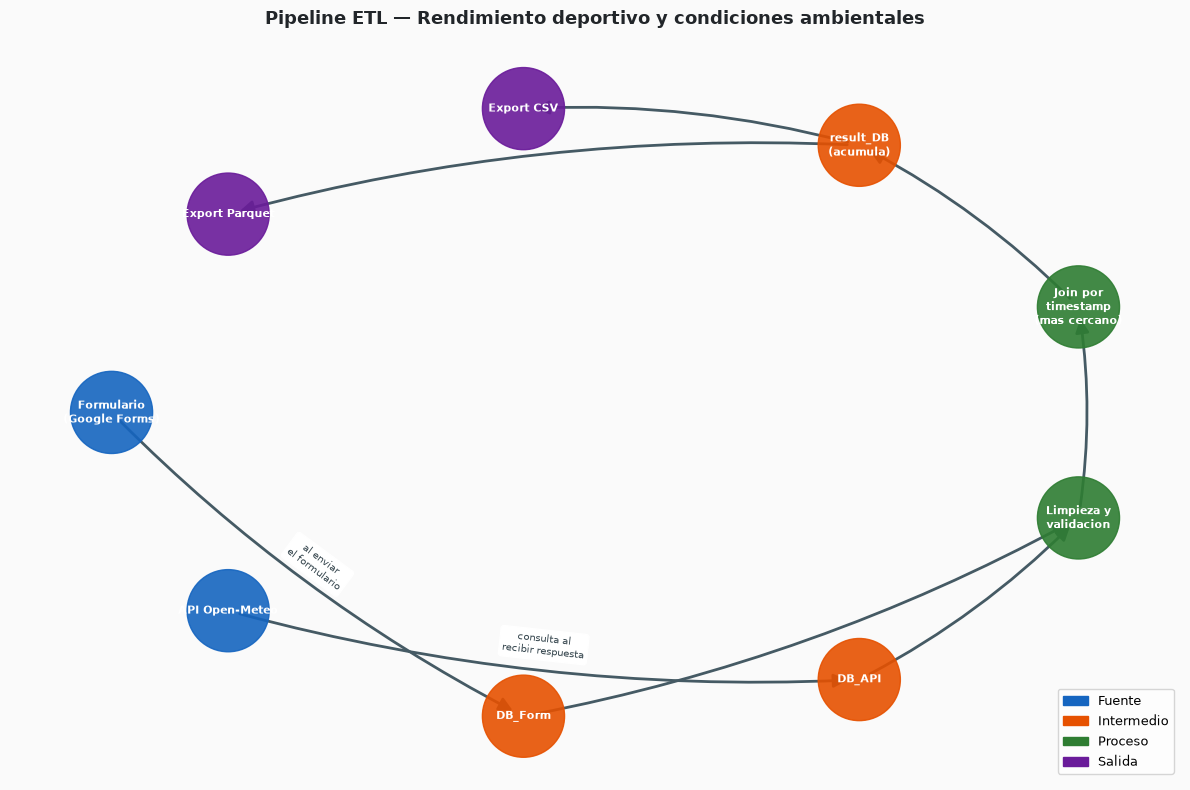

In [2]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

G = nx.DiGraph()

# ── NODOS ────────────────────────────────────────────────────────────────
# Modifica estas listas con los nodos de TU pipeline
# Grupos: 'fuente', 'intermedio', 'proceso', 'salida'
nodos = [
    # (nombre_nodo,              grupo)
    ('Formulario\n(Google Forms)',  'fuente'),
    ('API Open-Meteo',              'fuente'),
    ('DB_Form',                     'intermedio'),
    ('DB_API',                      'intermedio'),
    ('Limpieza y\nvalidacion',      'proceso'),
    ('Join por\ntimestamp\n(mas cercano)', 'proceso'),
    ('result_DB\n(acumula)',        'intermedio'),
    ('Export CSV',                  'salida'),
    ('Export Parquet',              'salida'),
]

# ── ARISTAS ──────────────────────────────────────────────────────────────
# (origen, destino, etiqueta opcional)
aristas = [
    ('Formulario\n(Google Forms)',  'DB_Form',                     'al enviar\nel formulario'),
    ('API Open-Meteo',              'DB_API',                      'consulta al\nrecibir respuesta'),
    ('DB_Form',                     'Limpieza y\nvalidacion',      ''),
    ('DB_API',                      'Limpieza y\nvalidacion',      ''),
    ('Limpieza y\nvalidacion',      'Join por\ntimestamp\n(mas cercano)', ''),
    ('Join por\ntimestamp\n(mas cercano)', 'result_DB\n(acumula)', ''),
    ('result_DB\n(acumula)',        'Export CSV',                   ''),
    ('result_DB\n(acumula)',        'Export Parquet',               ''),
]

# ── COLORES POR GRUPO ────────────────────────────────────────────────────
colores_grupo = {
    'fuente':      '#1565C0',
    'intermedio':  '#E65100',
    'proceso':     '#2E7D32',
    'salida':      '#6A1B9A',
}
color_nodo = {n: colores_grupo[g] for n, g in nodos}

G.add_nodes_from([n for n, _ in nodos])
G.add_edges_from([(o, d) for o, d, _ in aristas])

# ── LAYOUT ───────────────────────────────────────────────────────────────
pos = nx.drawing.layout.shell_layout(G)
# Si prefieres un layout manual, descomenta y ajusta:
# pos = {
#     'Formulario\n(Google Forms)': (0, 3),
#     'API Open-Meteo':             (4, 3),
#     'Respuestas\nformulario.csv': (0, 1.5),
#     'Lecturas\napi.csv':          (4, 1.5),
#     'Limpieza y\nvalidacion':     (2, 0.5),
#     'Join por\ntimestamp':        (2, -0.8),
#     'Dataset final\n(.parquet)':  (2, -2.2),
#     'Export CSV':                 (2, -3.5),
# }

fig, ax = plt.subplots(figsize=(12, 8))
fig.patch.set_facecolor('#FAFAFA')
ax.set_facecolor('#FAFAFA')

nx.draw_networkx_nodes(G, pos, ax=ax,
    node_color=[color_nodo[n] for n in G.nodes()],
    node_size=3500, alpha=0.9)

nx.draw_networkx_labels(G, pos, ax=ax,
    font_color='white', font_size=8, font_weight='bold')

nx.draw_networkx_edges(G, pos, ax=ax,
    edge_color='#455A64', arrows=True,
    arrowsize=20, width=2,
    connectionstyle='arc3,rad=0.08')

etiquetas_aristas = {(o, d): lbl for o, d, lbl in aristas if lbl}
nx.draw_networkx_edge_labels(G, pos, etiquetas_aristas, ax=ax,
    font_size=7, font_color='#37474F')

leyenda = [mpatches.Patch(color=c, label=g.capitalize())
           for g, c in colores_grupo.items()]
ax.legend(handles=leyenda, loc='lower right', fontsize=9)
ax.set_title('Pipeline ETL — ' + 'Rendimiento deportivo y condiciones ambientales',
             fontsize=13, fontweight='bold', color='#212529', pad=15)
ax.axis('off')
plt.tight_layout()
plt.show()

*(Si has modificado el grafo pero el layout automático no queda bien, descomenta el bloque `pos = { ... }` del código y ajusta las coordenadas de cada nodo manualmente hasta que quede claro y legible.)*


---
## 4. Limitaciones y mejoras futuras

Todo pipeline tiene limitaciones. Reflexiona sobre las tuyas y responde:

1. **¿Qué pasaría si la API dejara de estar disponible durante varios días?** ¿Cómo afectaría eso al dataset? ¿Cómo lo manejarías?

2. **¿Qué sesgo podría tener tu dataset?** Por ejemplo: ¿quién rellena el formulario? ¿Es una muestra representativa de la población que te interesa?

3. **¿Qué añadirías si tuvieras más recursos?** Por ejemplo: más fuentes de datos, mayor frecuencia de muestreo, un sistema de alertas automáticas...

*Responde aquí:*



*Escribe aquí tus respuestas:*

1. Si la API dejara de estar disponible varios días: las filas de esos días se quedarían sin datos climáticos, o con el último valor guardado en DB_API, que después de varios días ya no sería fiable. Esas filas se marcarían como incompletas en vez de rellenarlas con un dato inventado. Las respuestas del formulario no se perderían (se siguen guardando en DB_Form igualmente), y cuando la API volviera a funcionar se podría intentar completar esos huecos consultando el histórico de Open-Meteo, que sí permite pedir datos de fechas pasadas.

2. Sesgo del dataset: el principal es quién rellena el formulario. Si los participantes son conocidos míos o gente de un mismo grupo de edad y nivel físico, el dataset no representaría al deportista medio, estaría sesgado hacia ese perfil concreto y hacia los deportes que practica ese grupo. También hay sesgo de autoinforme: el esfuerzo percibido (1-10) es subjetivo y cada persona lo valora de forma distinta, así que no es directamente comparable entre usuarios.

3. Con más recursos: añadiría una fuente de datos objetiva, como un pulsómetro o smartwatch conectado por API, para no depender solo del esfuerzo percibido. También ampliaría el número de participantes para que la muestra sea más representativa, y añadiría un sistema de alertas que marque entrenamientos con valores claramente atípicos (por ejemplo, una distancia o duración imposible) para revisarlos antes de que entren en result_DB.
